Pearson correlation between ksm and loo: 0.973623
Pearson p-value: 0.000010


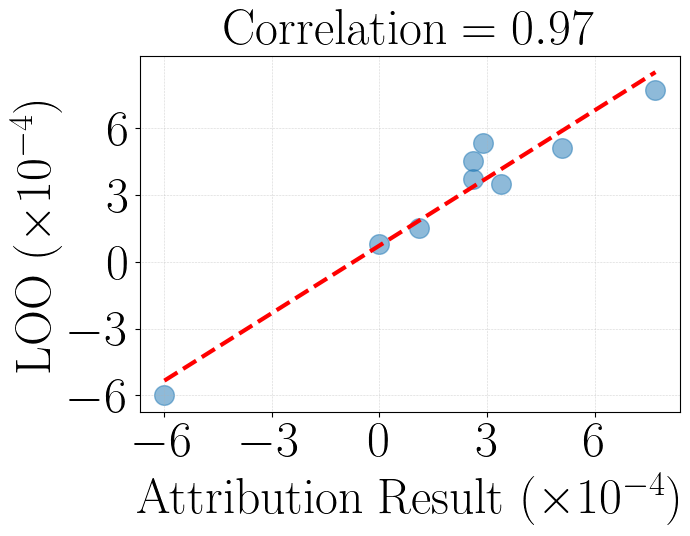

In [4]:
import math
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc
from scipy.stats import pearsonr

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker

loo = [
    -0.00060,
     0.00008,
     0.00015,
     0.00035,
     0.00053,
     0.00077,
     0.00037,
     0.00045,
     0.00051,
]
ksm = [
    -0.00060,
     0.00000,
     0.00011,
     0.00034,
     0.00029,
     0.00077,
     0.00026,
     0.00026,
     0.00051,
]


ksm = np.array(ksm) *1e4
loo = np.array(loo) *1e4

coeffs = np.polyfit(ksm, loo, 1)
fit_line = np.poly1d(coeffs)

x_vals = np.linspace(min(ksm), max(ksm), 500)
y_vals = fit_line(x_vals)

# Compute Pearson correlation
pearson_corr, pearson_p = pearsonr(ksm, loo)

print(f"Pearson correlation between ksm and loo: {pearson_corr:.6f}")
print(f"Pearson p-value: {pearson_p:.6f}")

fig, ax = plt.subplots(figsize=(7, 5))
plt.scatter(ksm, loo, s=200, alpha=0.5)
plt.plot(x_vals, y_vals, color='red', lw=3, ls='--', label=f"Fit: y={coeffs[0]:.2e}x + {coeffs[1]:.2e}")

#plt.xscale('log')  # Hessians vary widely, log scale makes it clearer
plt.xlabel(r"$\mathrm{Attribution~Result}~(\times 10^{-4})$", fontsize=36)
plt.xticks([-6, -3, 0, 3, 6], fontsize=36)
# ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
# ax.xaxis.offsetText.set_fontsize(36)

plt.ylabel(r"$\mathrm{LOO~}(\times 10^{-4})$", fontsize=36)
plt.yticks([-6, -3, 0, 3, 6], fontsize=36)
# ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# ax.yaxis.offsetText.set_fontsize(36)
#plt.title("Connection between Train Hessian and Datamodels Normalized Error", fontsize=40)
plt.grid(lw=0.4, ls=":")
plt.tight_layout()

title_name = r'$\mathrm{Correlation}=0.97$'
plt.title(title_name, fontsize=36)
plt.savefig("correlation_ksm_loo.pdf", format="pdf", dpi=1200, bbox_inches='tight')
plt.show()
